# 01 — Exploratory data analysis

What this notebook is for: check that the data is what we think it is, and
collect the evidence behind the modelling decisions in `src/retail_forecast/`.
Each section ends with the decision it supports.

Run `make data` first so `data/raw/` has the three CSVs.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

from retail_forecast.data import load_panel, load_raw

plt.rcParams.update({"figure.figsize": (10, 3.6), "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.3})
sales, stores, features = load_raw(ROOT / "data" / "raw")
df = load_panel(ROOT / "data" / "raw")
df.shape

(156000, 19)

## 1. Structure of the panel

In [2]:
summary = pd.Series({
    "rows": len(df),
    "stores": df.store_id.nunique(),
    "departments": df.department.nunique(),
    "weeks": df.date.nunique(),
    "first week": df.date.min().date(),
    "last week": df.date.max().date(),
    "series (store x dept)": df.groupby(["store_id", "department"]).ngroups,
    "missing values": int(df.isna().sum().sum()),
    "non-positive sales": int((df.weekly_sales <= 0).sum()),
})
summary.to_frame("value")

,value
rows,156000
stores,50
departments,20
weeks,156
first week,2022-01-01
last week,2024-12-21
series (store x dept),1000
missing values,0
non-positive sales,0


Every one of the 1,000 series has all 156 weeks, no gaps, no missing values
and no returns (non-positive sales). `load_panel` asserts the weekly calendar
is gap-free, so lags can be computed with a plain `shift`.

**Decision:** model at the store × department × week grain; no imputation
step is needed.

## 2. Where the variance is

In [3]:
total_var = df.weekly_sales.var()
series_mean = df.groupby(["store_id", "department"]).weekly_sales.transform("mean")
week_effect = df.groupby("date").weekly_sales.transform("mean") - df.weekly_sales.mean()
residual = df.weekly_sales - series_mean - week_effect

pd.Series({
    "between series (store x dept level)": series_mean.var() / total_var,
    "common weekly effect (calendar/holidays)": week_effect.var() / total_var,
    "left over": residual.var() / total_var,
}).round(3).to_frame("share of variance")

,share of variance
between series (store x dept level),0.429
common weekly effect (calendar/holidays),0.069
left over,0.502


About 43% of the variance is explained by *which* series a row belongs to and
about 7% by the week (holidays, mostly). The remaining ~50% is week-to-week
noise around each series' level. That remainder sets a floor on any forecast
error, and it is why WAPE stays around 43% even for the best model.

**Decision:** give the model store and department identity (v1 did not) and
a leak-free estimate of each series' level (the expanding mean).

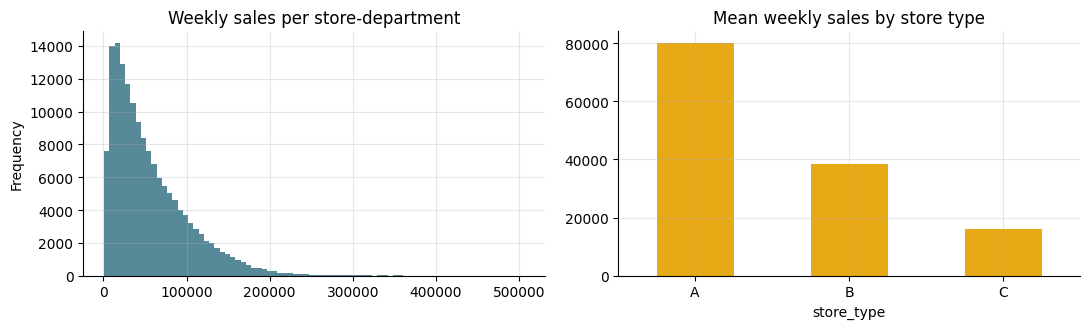

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
df.weekly_sales.plot.hist(bins=80, ax=axes[0], color="#568a99")
axes[0].set_title("Weekly sales per store-department")
df.groupby("store_type").weekly_sales.mean().plot.bar(ax=axes[1], color="#e8a917", rot=0)
axes[1].set_title("Mean weekly sales by store type")
plt.tight_layout()

## 3. Calendar and holidays

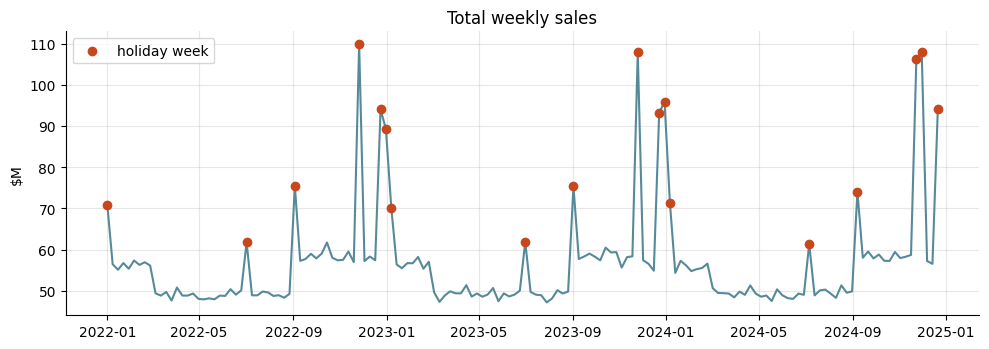

In [5]:
weekly_total = df.groupby("date").weekly_sales.sum() / 1e6
hol_weeks = pd.DatetimeIndex(df.loc[df.is_holiday == 1, "date"].unique())
fig, ax = plt.subplots()
ax.plot(weekly_total.index, weekly_total.to_numpy(), color="#568a99")
ax.scatter(hol_weeks, weekly_total.loc[hol_weeks].to_numpy(), color="#c8481c", zorder=3,
           label="holiday week")
ax.set_ylabel("$M"); ax.set_title("Total weekly sales"); ax.legend()
plt.tight_layout()

In [6]:
(df[df.is_holiday == 1]
   .drop_duplicates(["date", "holiday_name"])[["date", "holiday_name"]]
   .assign(year=lambda d: d.date.dt.year, date=lambda d: d.date.dt.strftime("%m-%d"))
   .groupby(["holiday_name", "year"]).date.apply(", ".join)
   .unstack())

year,2022,2023,2024
holiday_name,,,
Black Friday,11-26,11-25,"11-23, 11-30"
Christmas,"12-24, 12-31","12-23, 12-30",12-21
Independence Day,07-02,07-01,07-06
Labor Day,09-03,09-02,09-07
New Year,01-01,01-07,01-06


Outside the holiday weeks the total is almost flat — there is no trend and
little seasonality beyond the holidays themselves. The holiday tagging is not
perfectly regular (Black Friday is tagged on two weeks in 2024, Christmas on
two weeks in 2022 and 2023 but one in 2024).

**Decision:** pass `holiday_name` as a categorical (each event has a very
different lift) and weight holiday weeks 5× in training and evaluation
(WMAE), as in the original competition.

## 4. Do the macro / markdown columns carry signal?

In [7]:
exo = ["temperature", "fuel_price", "cpi", "unemployment",
       "markdown_1", "markdown_2", "markdown_3", "markdown_4", "markdown_5"]
f = features.sort_values(["store_id", "date"])
autocorr = {c: f.groupby("store_id")[c].apply(lambda s: s.autocorr()).mean() for c in exo}
resid_corr = df.assign(resid=residual)[exo].corrwith(df.assign(resid=residual).resid)
pd.DataFrame({"lag-1 autocorrelation": autocorr,
              "corr. with residual sales": resid_corr}).round(3)

,lag-1 autocorrelation,corr. with residual sales
temperature,-0.002,-0.000
fuel_price,-0.007,-0.002
cpi,-0.014,0.003
unemployment,-0.034,-0.007
markdown_1,0.037,-0.004
markdown_2,0.054,0.000
markdown_3,0.054,-0.004
markdown_4,0.031,0.001
markdown_5,0.038,0.001


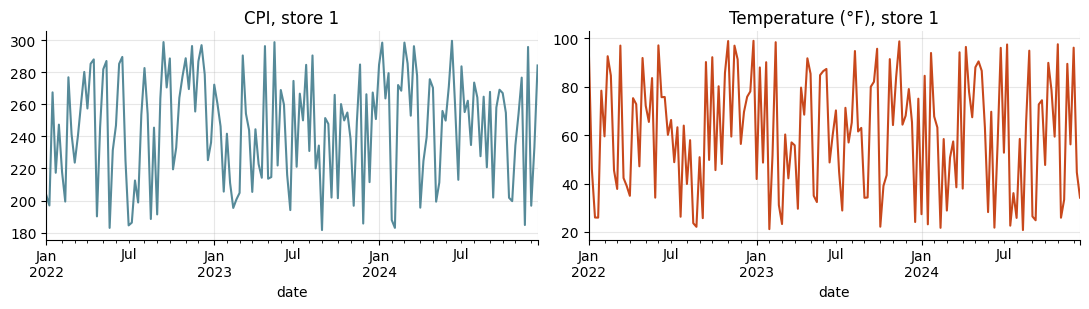

In [8]:
one = f[f.store_id == 1].set_index("date")
fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
one.cpi.plot(ax=axes[0], color="#568a99", title="CPI, store 1")
one.temperature.plot(ax=axes[1], color="#c8481c", title="Temperature (°F), store 1")
plt.tight_layout()

This is the most important finding about the dataset. In real data CPI and
unemployment move slowly and temperature follows the seasons. Here every one
of these columns behaves like an independent draw each week (lag-1
autocorrelation ≈ 0; CPI jumps between ~180 and ~300 from one week to the
next) and none of them correlates with the part of sales the series level
and calendar do not explain. They were almost certainly generated at random
when the dataset was adapted.

**Decision:** leave them out of the model. They would not be known ahead of
time in a real forecast anyway. The pipeline runs an ablation that adds them
back to confirm there is no loss (holdout WMAE 31,850 without vs. 31,852
with).

## 5. How much does recent history help?

In [9]:
s = df.sort_values(["store_id", "department", "date"]).copy()
g = s.groupby(["store_id", "department"]).weekly_sales
dev = s.weekly_sales - g.transform("mean")
s["dev"] = dev
gd = s.groupby(["store_id", "department"]).dev
pd.Series({f"lag {k}": s.dev.corr(gd.shift(k)) for k in (1, 2, 4, 13, 52)}
          ).round(3).to_frame("autocorrelation of deviations from series mean")

,autocorrelation of deviations from series mean
lag 1,0.062
lag 2,0.024
lag 4,0.054
lag 13,-0.014
lag 52,0.120


Once each series' level is removed, last week's deviation barely predicts
this week's (lag-1 autocorrelation ≈ 0.06). The strongest one is lag 52
(≈ 0.12), which is the holiday pattern repeating, not momentum. Lags mostly
help the model estimate the level and holiday response of each series.

**Decision:** keep lags and rolling means (they are cheap and help the
level estimate), but expect the error to be roughly flat across forecast
horizons — which is what the direct multi-horizon evaluation shows.

## Summary

| Finding | Decision |
|---|---|
| Balanced, gap-free weekly panel | Lags via `shift`; no imputation |
| Series level explains most variance | Store/dept identity + expanding mean |
| Holidays are the main calendar effect, with very different sizes | `holiday_name` categorical, 5× weight (WMAE) |
| Macro/markdown columns look like random noise | Excluded; ablation confirms no loss |
| Little short-term momentum | Flat error across horizons; direct models per horizon |